# Part 1：深度學習基礎（Deep Learning Fundamentals）｜版本 2

從一個神經元開始，用 PyTorch 完成顧客購買預測。

你已經會使用 Python、Pandas，以及基本的分類概念，但第一次看到神經網路程式時，可能會想：`Linear(4, 16)` 的數字是哪來的？模型到底學了什麼？為什麼預測之前要標準化？這份教材會一邊解釋，一邊用可以執行的小例子回答。

完成後，你應該能做到：

- 用白話解釋神經元、Weight、Bias、Weighted Sum 與前向傳播。
- 根據 Features 與 Target 決定輸入、隱藏與輸出層。
- 解讀 Tensor 的 shape、dtype，以及 PyTorch 常用參數。
- 從 CSV 開始，完成訓練、預測、評估與結果視覺化。
- 分辨訓練表現與未知資料表現，並用相同前處理預測新資料。

**閱讀方式**：先讀觀念，再由上往下執行所有程式儲存格。前面的迷你範例與後面的完整專案使用不同變數名稱。安裝指令放在文字區塊，不會在 Run All 時自動安裝。

**資料說明**：使用附帶的 3,000 筆人工合成資料，不需帳號、不需下載外部資料。這是教學練習，成績不代表真實商業預測能力。程式輸出會因套件、裝置與版本略有差異，請以自己執行的結果解讀。


## 教材導覽

| 區段 | 核心問題 | 你會做出什麼 |
| --- | --- | --- |
| 1. ML 與 DL | 神經網路適合處理什麼？ | 確認分類任務與資料 |
| 2. ANN 與神經元 | 模型如何把輸入變成分數？ | 手算與程式對照 |
| 3. 網路層與前向傳播 | 資料怎麼通過多層網路？ | 讀懂 4 → 16 → 8 → 1 |
| 4. PyTorch 基礎 | 如何把觀念寫成程式？ | Tensor、Linear、Sequential |
| 5. 完整專案 | 如何從資料走到可用預測？ | 八個主要實作步驟 |
| 6. 延伸與練習 | 如何保存成果、排錯與調整？ | 新客戶預測、模型保存、練習 |

數學只保留能幫助操作的簡單加乘。ReLU、Loss、Optimizer 與 Backpropagation 在這裡先建立使用觀念，後續章節再深入原理。


## 1. 機器學習與深度學習（Machine Learning vs Deep Learning）

### 1.1 從寫規則到讓模型學規律

假設商店想知道誰可能購買商品。人工規則可以寫成「到訪 8 次以上就推薦」，但某些顧客來得少、消費卻很高，單一規則可能漏掉他們。

機器學習把「顧客資料」與「過去是否購買」一起交給模型，讓模型從範例找出預測規律。訓練完成後，再輸入沒有答案的新資料。

```text
訓練：歷史 Features + 已知 Target → 學習規律 → 訓練後模型
預測：新顧客 Features + 訓練後模型 → 預測結果
```

**Features（特徵）**是預測時能取得的輸入；**Target（目標）**是想預測的答案。這次 Target 只有購買與不購買，因此是**監督式學習中的二元分類**。

### 1.2 深度學習是機器學習的一部分

```text
人工智慧 AI
└── 機器學習 ML
    └── 深度學習 DL
```

深度學習使用多層神經網路，逐層轉換資料表示。影像可以從簡單的邊緣逐步形成較複雜的表示；表格資料則可以學到多個欄位之間的組合關係。

| 比較項目 | 傳統機器學習常見情況 | 深度學習常見情況 |
| --- | --- | --- |
| 例子 | Logistic Regression、樹模型、SVM | MLP、CNN、Transformer |
| 特徵處理 | 常仰賴欄位設計與前處理 | 可從資料學到多層表示，仍需要適當前處理 |
| 表格資料 | 常是很好的起點 | 可以使用，但不保證勝過樹模型 |
| 資料與運算 | 許多模型能處理小資料、使用 CPU | 大型模型通常需要更多資料與運算 |
| 解釋結果 | 視模型而定 | 多層表示較難直接解釋 |

這次使用小型表格 ANN，是為了看懂完整流程。模型更深、參數更多、使用 GPU，都不能保證成績更好。後面會加上 Logistic Regression 作為比較依據。


### 圖片規劃：AI、ML 與 DL 的關係

圖片名稱：`01_ml_dl_relationship.png`  
尺寸：**1280 × 720，16:9**  
建議存放：`assets/v2/01_ml_dl_relationship.png`

> 提示詞：製作繁體中文深度學習教材示意圖。橫向 16:9，1280 × 720 px，白色背景，深藍標題、藍綠色重點、橘色強調，扁平向量資訊圖風格。字體大且清晰，資訊有留白，箭頭方向明確，不使用裝飾性假公式、不加浮水印。左側用三層包含關係顯示 AI 包含 ML、ML 包含 DL；右側用平行兩列顯示傳統機器學習與深度學習的典型流程，兩者皆含前處理。底部一句『依資料與驗證結果選模型』。不要畫成兩個互斥領域。

這是待製作圖片的規劃；目前先用相鄰文字與流程圖閱讀，不需要圖片也能完成本節。


## 2. 人工神經網路（Artificial Neural Network, ANN）

### 2.1 把網路想成一組可以調整的計算單元

ANN 由許多神經元與連接組成。每個神經元接收數字、運算，再把結果交給後面的神經元。名字受到生物神經系統啟發，但它不是完整的人腦模擬。

可以把它想成一間分工的廚房：食材是輸入，前面幾站處理原料，後面組合成一道料理。訓練則像根據試吃回饋調整配方。這只是理解分工的比喻，實際運作仍是數值計算。

本章建立的 ANN 是 **多層感知器（MLP）**：使用全連接層，讓資料由前往後傳遞。ANN 是較廣的名稱；CNN 等模型也屬於神經網路家族。MLP 是本章練習的具體架構。

### 2.2 模型真正學到的是什麼？

不是把每位顧客的 CSV 整份塞進模型。訓練會調整各層的 **Weight 與 Bias**，讓整體輸出更接近答案。這些可調整數值叫做**模型參數**。

模型也可能記住訓練資料中的偶然細節，卻無法處理新顧客，所以必須保留沒有參與訓練的資料來評估。


## 3. 神經元（Neuron）：Weight、Bias 與 Weighted Sum

### 3.1 先把一個神經元看成一台評分機

假設只用兩個特徵評分：到訪次數與瀏覽次數。每個數值先乘上各自權重，再加起來，最後加上偏差。

| 名稱 | 白話意思 | 例子 |
| --- | --- | --- |
| 輸入 x | 這筆資料的特徵值 | 到訪 5 次、瀏覽 3 次 |
| 權重 Weight | 調整每個輸入對分數的影響 | 到訪乘 0.8、瀏覽乘 0.4 |
| 加權總和 Weighted Sum | 先乘權重，再把結果加起來 | 5 × 0.8 + 3 × 0.4 = 5.2 |
| 偏差 Bias | 與這筆輸入無關、可學習的基準位移 | 再加上 −2，得到 3.2 |
| 活化函數 Activation | 對分數做轉換，常用於引入非線性 | 隱藏層常用 ReLU |

本教材把「加權總和」稱為各個 x × w 的總和；加上 Bias 後的結果稱為 **z**。有些教材也會把含 Bias 的運算一起稱為加權總和，閱讀時要看清楚定義。

```text
到訪 5 ── × 0.8 ── 4.0 ──┐
                          ├── 相加 5.2 ── 加 Bias(-2) ── z = 3.2
瀏覽 3 ── × 0.4 ── 1.2 ──┘
```

只需要記住這一行：**神經元的基礎運算 = 每項輸入乘上權重，加總後再加偏差。**

### 3.2 權重的正負與大小

在這個單一神經元中，其他輸入固定時，正權重讓該輸入增加時分數提高；負權重讓分數降低。權重為 0，代表這條連接當下沒有貢獻。

但不能看到收入權重比較大，就宣稱收入最重要。輸入單位、其他層與特徵關係都會影響解讀；網路權重也不是因果證據。

### 3.3 Bias 為什麼有用？

Bias 讓神經元不用強迫「輸入全部為 0 時，基礎分數一定為 0」。它可以上下移動整個評分基準，是模型一起學習的參數。它不是分類門檻，也不是統計學裡的模型偏誤。

下面先手動設定 Weight 與 Bias，方便核對運算。完整專案會交給訓練流程學習，不會手動替模型寫答案。


In [1]:
### 先用純 Python 看清楚單一神經元的計算
visit_count = 5.0
browse_count = 3.0
visit_weight = 0.8
browse_weight = 0.4
bias_value = -2.0

### 各項輸入先乘以自己的權重，再加總
weighted_sum = visit_count * visit_weight + browse_count * browse_weight
neuron_score = weighted_sum + bias_value
print(f"加權總和：{weighted_sum:.1f}")  # 5.2
print(f"加上 Bias 後的分數：{neuron_score:.1f}")  # 3.2，不是機率


加權總和：5.2
加上 Bias 後的分數：3.2


### 小練習：不用重新訓練也能理解運算

把 `visit_weight` 改成 −0.8，其他數值不變，分數會變成 −4.8。把 `bias_value` 從 −2 改成 0，原本分數則從 3.2 變成 5.2。

重點是辨認每個數值的角色。真正訓練時，模型會同時調整很多神經元的 Weight 與 Bias，不是只改一個數字。


### 圖片規劃：一個神經元如何評分

圖片名稱：`02_neuron_weight_bias.png`  
尺寸：**1280 × 720，16:9**  
建議存放：`assets/v2/02_neuron_weight_bias.png`

> 提示詞：製作繁體中文深度學習教材示意圖。橫向 16:9，1280 × 720 px，白色背景，深藍標題、藍綠色重點、橘色強調，扁平向量資訊圖風格。字體大且清晰，資訊有留白，箭頭方向明確，不使用裝飾性假公式、不加浮水印。用兩條輸入路徑呈現到訪 5 × Weight 0.8 = 4.0，瀏覽 3 × Weight 0.4 = 1.2；匯入加總節點得到 5.2，再由獨立 Bias −2 箭頭加入得到 z=3.2。右側標示『這是分數，尚未轉成機率』。清楚區分 Weight 與 Bias。

這是待製作圖片的規劃；目前先用相鄰文字與流程圖閱讀，不需要圖片也能完成本節。


## 4. 輸入層、隱藏層與輸出層

### 4.1 輸入層（Input Layer）：每筆資料有多少 Features？

本章完整專案使用年齡、月收入、過去一個月到訪次數，以及過去平均消費，共 4 個特徵。因此第一個全連接層必須接收 4 個數值。

**輸入特徵數由欄位數決定，不是由資料筆數決定。** 3,000 位顧客，每人 4 個特徵，輸入 shape 就是 `(3000, 4)`。Target 不放進輸入。MLP 通常不需要另外建立一個叫做 InputLayer 的物件。

### 4.2 隱藏層（Hidden Layer）：把輸入轉成新的表示

隱藏層不直接收到「每個神經元該代表什麼」的答案，而是配合最後的預測誤差一起調整。有的組合可能對「高到訪、高消費」有反應，但不能預先保證某個神經元一定代表「忠誠度」。

本章先設定兩個隱藏層：16 個、8 個神經元。這些數字是**設計選擇**，不是固定規則。太少可能學不夠；太多可能增加成本、過度擬合。要看驗證結果判斷。

### 4.3 輸出層（Output Layer）：你想得到哪種答案？

| 任務 | 常見輸出設計 | 後續解讀 |
| --- | --- | --- |
| 預測單一房價 | 1 個連續數值 | 直接解讀數值 |
| 是否購買（二元分類） | 1 個 Logit | Sigmoid → 正類機率估計 |
| 三選一商品類別 | 3 個 Logits | Softmax → 各類機率估計 |
| 多個標籤可同時成立 | 每個標籤 1 個 Logit | 每項各自 Sigmoid |

二元分類也能設計成兩個輸出，但那會使用另一種損失設定。本章統一使用 **1 個輸出 + BCEWithLogitsLoss**，避免混用。

### 4.4 本章網路的資料流

```text
每位顧客 4 個特徵
    ↓ Linear(4, 16)
16 個新數值 → ReLU
    ↓ Linear(16, 8)
 8 個新數值 → ReLU
    ↓ Linear(8, 1)
 1 個 Logit → 預測時 Sigmoid → 機率估計 → 分類門檻 → 0 或 1
```

這裡共有 3 個有參數的 Linear 層：2 個隱藏層與 1 個輸出層。有人會連輸入層一起稱為 4 層網路，因此討論層數時最好直接列出架構。


### 圖片規劃：4 → 16 → 8 → 1 網路架構

圖片名稱：`03_ann_layers.png`  
尺寸：**1280 × 720，16:9**  
建議存放：`assets/v2/03_ann_layers.png`

> 提示詞：製作繁體中文深度學習教材示意圖。橫向 16:9，1280 × 720 px，白色背景，深藍標題、藍綠色重點、橘色強調，扁平向量資訊圖風格。字體大且清晰，資訊有留白，箭頭方向明確，不使用裝飾性假公式、不加浮水印。由左至右畫輸入4節點、隱藏層16節點、隱藏層8節點、輸出1節點。16節點可採部分節點加省略號，但標示實際16個。兩個隱藏層後標示 ReLU，輸出後另列 Sigmoid 與 threshold 0.5。底部標示一批32筆的 shape：(32,4)→(32,16)→(32,8)→(32,1)。不要把 Sigmoid 畫在訓練模型內。

這是待製作圖片的規劃；目前先用相鄰文字與流程圖閱讀，不需要圖片也能完成本節。


## 5. 全連接層（Fully Connected Layer）

全連接層也常稱 Dense Layer：上一層的每個輸出，都連到下一層的每個神經元。每條線有自己的 Weight；每個輸出神經元有自己的 Bias。

例如 4 個輸入接到 3 個輸出：共有 4 × 3 = 12 個權重，加上 3 個偏差，一共 15 個可學習參數。**增加資料筆數不會增加模型參數量**，因為不同顧客共用同一組參數。

PyTorch 用 `nn.Linear(in_features, out_features, bias=True)` 表達這一層。名稱 Linear 在這裡實際包含加 Bias 的仿射轉換。這層只負責計算，不會自動訓練。

| 參數／屬性 | 意思 | 4 → 3 的例子 |
| --- | --- | --- |
| `in_features` | 每筆資料輸入幾個數值 | 4 |
| `out_features` | 每筆資料輸出幾個數值 | 3 |
| `bias` | 是否建立可學習偏差，預設 True | 每個輸出一個 |
| `.weight.shape` | 權重排列是「輸出數 × 輸入數」 | `(3, 4)` |
| `.bias.shape` | 每個輸出神經元的偏差 | `(3,)` |

完整專案參數數量：4 → 16 是 80 個；16 → 8 是 136 個；8 → 1 是 9 個，總計 **225 個**。


### 圖片規劃：全連接層的 15 個參數

圖片名稱：`04_fully_connected.png`  
尺寸：**1280 × 720，16:9**  
建議存放：`assets/v2/04_fully_connected.png`

> 提示詞：製作繁體中文深度學習教材示意圖。橫向 16:9，1280 × 720 px，白色背景，深藍標題、藍綠色重點、橘色強調，扁平向量資訊圖風格。字體大且清晰，資訊有留白，箭頭方向明確，不使用裝飾性假公式、不加浮水印。左側4個輸入節點、右側3個輸出節點，畫出全部12條連線；每個輸出旁再畫獨立Bias，共3個。右下角標示『4×3個Weight + 3個Bias = 15個參數』。用單一輸出神經元的4條連線加深色，其餘線淡色降低雜訊。

這是待製作圖片的規劃；目前先用相鄰文字與流程圖閱讀，不需要圖片也能完成本節。


## 6. 前向傳播（Forward Propagation）

### 6.1 資料走過網路，得到結果

前向傳播就是把資料放進模型，依照層的順序運算到輸出。它可以發生在訓練、驗證或正式預測中。**前向傳播本身不會更新參數**。

```text
訓練：輸入 → Forward → Loss → Backward → Optimizer 更新參數 → 下一輪
預測：輸入 → Forward → 機率與類別
```

Loss 是預測與答案之間的差距分數，Backward 計算參數調整所需的梯度，Optimizer 根據梯度實際更新參數。先理解分工就能操作，暫時不用推導微分。

### 6.2 為什麼中間需要 ReLU？

如果只連續堆疊 Linear，中間沒有非線性轉換，整體仍可以合併成單一仿射轉換。增加層數也不會因此得到真正的非線性表達能力。

ReLU 的規則很簡單：負值變 0，正值保留。例如 `[-2, 0, 3] → [0, 0, 3]`。它讓網路的數值轉換具有轉折，能組合出更複雜的關係。它不是把數字轉成機率的函數。

### 6.3 Logit、機率估計與類別是三種東西

| 名稱 | 範圍 | 用途 |
| --- | --- | --- |
| Logit | 任意實數 | 模型輸出的原始分數，交給 Loss |
| Sigmoid 後的數值 | 0～1 | 正類機率估計 |
| 預測類別 | 0 或 1 | 依門檻決定的答案 |

Logit 為 0，Sigmoid 後是 0.5；正分數對應大於 0.5，負分數對應小於 0.5。0.82 可以解讀為模型的 82% 機率估計，但不能因此保證每 100 位這類顧客就剛好 82 位購買，校準程度需要另外評估。

門檻 0.5 是起點。若調低門檻，通常能找出更多可能購買者，也會帶來更多誤報；門檻應依實際目的用驗證集決定，不能看完測試答案才挑最好看的門檻。


### 圖片規劃：前向傳播與訓練的差別

圖片名稱：`05_forward_training.png`  
尺寸：**1280 × 720，16:9**  
建議存放：`assets/v2/05_forward_training.png`

> 提示詞：製作繁體中文深度學習教材示意圖。橫向 16:9，1280 × 720 px，白色背景，深藍標題、藍綠色重點、橘色強調，扁平向量資訊圖風格。字體大且清晰，資訊有留白，箭頭方向明確，不使用裝飾性假公式、不加浮水印。上排藍色箭頭依序表示 Features→Linear/ReLU→Logit→Sigmoid→Prediction，標『預測流程』。下排表示 Features→模型→Logit→與Target計算Loss→Backward計算梯度→Optimizer更新Weight/Bias，再回到模型；Backward用橘色，清楚標示梯度計算與更新參數是不同動作。

這是待製作圖片的規劃；目前先用相鄰文字與流程圖閱讀，不需要圖片也能完成本節。


## 7. PyTorch 基本介紹（Introduction to PyTorch）

PyTorch 提供數值運算、神經網路元件、自動微分與裝置運算工具。你負責安排資料、架構與訓練流程；框架協助計算梯度。

| 工具 | 本章用途 |
| --- | --- |
| `torch` | 建立 Tensor、設定隨機種子與儲存參數 |
| `torch.nn` | `Linear`、`ReLU`、`Sequential`、Loss |
| `torch.optim` | 使用 Adam 更新參數 |
| `torch.utils.data` | TensorDataset 與 DataLoader 分批讀資料 |
| `torch.no_grad()` | 在驗證與預測時停止記錄梯度 |

### 7.1 安裝與 Notebook Kernel

如果你已經有能正常執行第一版的環境，可直接選原本的 Kernel。若從零開始，建議在新的教材資料夾使用 Python 3.12 建立環境，以下在 PowerShell 執行，**不是 Python 儲存格**：

```powershell
uv venv --python 3.12
uv pip install --python .venv/Scripts/python.exe torch --index-url https://download.pytorch.org/whl/cpu
uv pip install --python .venv/Scripts/python.exe numpy pandas scikit-learn matplotlib ipykernel
```

`uv venv` 建立環境；`--python` 指定目標 Python；CPU 安裝來源讓入門練習不依賴 CUDA。這個小模型使用 CPU 就能完成。

在 VS Code 右上角 **Select Kernel → Python Environments** 選剛建立的 `.venv`。安裝完請重新啟動 Kernel。若使用 NVIDIA GPU，請依 [PyTorch 官方安裝選擇器](https://pytorch.org/get-started/locally/) 確認作業系統、驅動與安裝版本；不要只憑 `nvidia-smi` 顯示的 CUDA 數字猜指令。該數字表示驅動支援能力，不等於 PyTorch 所使用的 CUDA runtime。

不用為了這份表格教材安裝 torchvision 或 torchaudio。套件安裝在終端機的環境與 Notebook Kernel 必須一致。


In [2]:
import sys
import torch
import torch.nn as nn
import numpy as np

### 檢查目前真正使用的 Python 與 PyTorch
print("Python 路徑：", sys.executable)
print("PyTorch 版本：", torch.__version__)
print("PyTorch CUDA runtime：", torch.version.cuda)
print("CUDA 可用：", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU 名稱：", torch.cuda.get_device_name(0))


Python 路徑： D:\github\python-deep-learning\.venv\Scripts\python.exe
PyTorch 版本： 2.11.0+cu128
PyTorch CUDA runtime： 12.8
CUDA 可用： True
GPU 名稱： NVIDIA GeForce RTX 5060


### 7.2 Tensor：模型使用的數值容器

Tensor 可以是單一數值、向量或多維陣列。與 NumPy 相似，但可以配合自動微分與 GPU。shape 代表每個維度的長度，dtype 代表資料型別，device 代表目前所在裝置。

| 維度 | 範例 | shape |
| --- | --- | --- |
| 0D | 一個分數 | `()` |
| 1D | 一筆資料的四個特徵 | `(4,)` |
| 2D | 兩筆資料，各四個特徵 | `(2, 4)` |

本章統一將表格 Features 整理成 `(筆數, 特徵數)`。即使只有一位新顧客，也保留 `(1, 4)`。使用 float32，是為了配合模型預設的浮點參數型別；不是因為年齡突然可以有小數才這樣轉。


In [3]:
### 不同維度的 Tensor
demo_scalar = torch.tensor(5.0)  # 單一數值
demo_vector = torch.tensor([1.0, 2.0, 3.0, 4.0])  # 一維
demo_matrix = torch.tensor([[25, 50000, 5, 2000], [35, 70000, 8, 3500]],
                           dtype=torch.float32)  # 兩筆、四欄
for tensor_name, tensor_value in [("scalar", demo_scalar), ("vector", demo_vector),
                                  ("matrix", demo_matrix)]:
    print(tensor_name, "shape=", tuple(tensor_value.shape),
          "dtype=", tensor_value.dtype, "device=", tensor_value.device)

### NumPy 與 Tensor 的互轉
demo_array = np.array([[1.0, 2.0]], dtype=np.float32)
demo_from_numpy = torch.from_numpy(demo_array)  # 通常共用記憶體，修改時要注意
demo_numpy_back = demo_from_numpy.detach().cpu().numpy()
print("轉回 NumPy：", demo_numpy_back)


scalar shape= () dtype= torch.float32 device= cpu
vector shape= (4,) dtype= torch.float32 device= cpu
matrix shape= (2, 4) dtype= torch.float32 device= cpu
轉回 NumPy： [[1. 2.]]


`.detach()` 將結果脫離梯度追蹤；`.cpu()` 把資料移回 CPU；`.numpy()` 再轉 NumPy。後面的 sklearn 評估與 Pandas 表格會用到這組操作。

### 7.3 用 nn.Linear 重現剛剛的神經元

`nn.Linear(2, 1)` 是接收兩個特徵、輸出一個分數。`torch.no_grad()` 在這裡是為了手動寫入示範參數，避免記錄這段設定操作；它不代表之後無法訓練。


In [4]:
### 一筆資料、兩個特徵
demo_input = torch.tensor([[5.0, 3.0]], dtype=torch.float32)
demo_neuron = nn.Linear(in_features=2, out_features=1, bias=True)

### 只為了教學，指定與手算相同的權重與偏差
with torch.no_grad():
    demo_neuron.weight.copy_(torch.tensor([[0.8, 0.4]]))
    demo_neuron.bias.copy_(torch.tensor([-2.0]))
    demo_output = demo_neuron(demo_input)

print("神經元輸出：", demo_output.item())  # 約 3.2，浮點運算可能有細微誤差
print("Weight shape：", tuple(demo_neuron.weight.shape))  # (1, 2)
print("Bias shape：", tuple(demo_neuron.bias.shape))  # (1,)


神經元輸出： 3.1999998092651367
Weight shape： (1, 2)
Bias shape： (1,)


### 7.4 觀察全連接層與逐層 shape

`nn.Sequential` 將模組依照順序串起來。呼叫 `model(X)` 時，PyTorch 依序執行每個模組。下面只觀察資料流，不進行訓練。隨機初始化的結果沒有可靠預測意義。


In [5]:
torch.manual_seed(42)  # 固定示範初始化，方便重做
demo_fc = nn.Linear(in_features=4, out_features=3, bias=True)
print("4 → 3 的 Weight：", tuple(demo_fc.weight.shape))
print("4 → 3 的參數數量：", sum(p.numel() for p in demo_fc.parameters()))

demo_network = nn.Sequential(
    nn.Linear(4, 16),  # 每筆 4 個輸入 → 16 個數值
    nn.ReLU(),        # 引入非線性，shape 不變
    nn.Linear(16, 8),
    nn.ReLU(),
    nn.Linear(8, 1),   # 輸出 Logit，還不是機率
)
demo_batch = torch.tensor([[0.2, 0.5, 0.3, 0.8], [0.7, 0.4, 0.9, 0.6]],
                          dtype=torch.float32)
with torch.no_grad():
    demo_values = demo_batch
    print("輸入：", tuple(demo_values.shape))
    for demo_layer in demo_network:
        demo_values = demo_layer(demo_values)
        print(type(demo_layer).__name__, "→", tuple(demo_values.shape))
    print("未訓練的機率估計：", torch.sigmoid(demo_values))


4 → 3 的 Weight： (3, 4)
4 → 3 的參數數量： 15
輸入： (2, 4)
Linear → (2, 16)
ReLU → (2, 16)
Linear → (2, 8)
ReLU → (2, 8)
Linear → (2, 1)
未訓練的機率估計： tensor([[0.4296],
        [0.4297]])


### 7.5 自我檢查

1. 有 500 筆資料、每筆 6 個 Features，第一層應設 `in_features=6`，不是 500。
2. `Linear(6, 10)` 有 60 個 Weight 與 10 個 Bias，共 70 個參數。
3. 一批 32 筆資料經過這一層，shape 從 `(32, 6)` 變成 `(32, 10)`。
4. 前向傳播會用到目前參數；只有配合反向傳播與更新步驟，參數才會學習改變。


## 8. 完整專案：預測顧客是否購買商品

### 8.1 定義預測時點，避免偷看答案

想像商店在行銷活動開始前，整理每位顧客當時可取得的歷史資訊，預測活動期間是否購買。`Visits` 與 `Avg_Spending` 必須來自活動前，不能包含目標期間的結果。

若拿「這次購買總額」去預測「這次是否購買」，模型等於提前看到了答案，稱為**資料洩漏（Data Leakage）**。再高的測試分數也沒有實用意義。

### 8.2 這次準備好的資料

檔案：`data/customer_purchase_v2.csv`，共 3,000 列，每列是一位虛構顧客。

| 欄位 | 角色 | 說明 | 生成範圍 |
| --- | --- | --- | --- |
| `Customer_ID` | 識別碼 | 區分資料列，不作為輸入 | C00001 起 |
| `Age` | Feature | 年齡，歲 | 18～70 |
| `Monthly_Income` | Feature | 月收入，元 | 22,000～120,000 |
| `Visits` | Feature | 過去一個月到訪次數 | 0～20 |
| `Avg_Spending` | Feature | 過去歷史平均每次消費，元 | 100～6,000 |
| `Purchased` | Target | 目標期間是否購買 | 0 或 1 |

資料根據數個特徵、交互作用與隨機購買行為合成，並非保證每個高收入者都購買。故意保留不確定性，讓學生理解正確流程也不必然得到 100% 準確率。這份資料預設沒有缺值或重複列，但仍示範檢查。生成方式、限制與重建指令另見 `data/資料說明_v2.md`。

### 8.3 八個主要步驟

1. 讀取資料集：同時檢查品質與分布。
2. 選擇 Features 與 Target：排除 ID 與答案。
3. 切分 Train / Test：另外從訓練部分保留 Validation，再標準化與轉 Tensor。
4. 建立模型：決定架構、Loss 與 Optimizer。
5. 訓練模型：分批更新，根據驗證集保存最佳參數。
6. 使用模型預測：將分數轉成機率與類別。
7. 評估模型表現：同時查看基準模型與多種指標。
8. 視覺化預測結果：Loss、混淆矩陣、ROC 與機率分布。


## 9. 步驟一：讀取資料集

### 9.1 匯入工具與設定

完整專案從這裡開始，所需套件重新集中匯入。預設優先使用可用的 CUDA GPU，也可以把 `DEVICE_CHOICE` 改成 `"cpu"`。小型模型的 GPU 可能因資料傳輸成本而沒有比較快。

固定種子讓同環境較容易重現；不同裝置與套件版本仍可能不同。`OUTPUT_DIR` 會收集圖表、預測表與模型，避免散落各處。


In [6]:
from pathlib import Path
from copy import deepcopy
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from IPython.display import display

### 所有可調整的訓練設定集中在這裡
SEED = 42
DEVICE_CHOICE = "auto"  # 改成 "cpu" 可強制使用 CPU
BATCH_SIZE = 64
LEARNING_RATE = 0.001
MAX_EPOCHS = 150
PATIENCE = 20
THRESHOLD = 0.5  # 本章先固定，不根據 Test 挑選

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if DEVICE_CHOICE == "auto" and torch.cuda.is_available()
                      else "cpu")

### 支援從本教材資料夾或上一層專案根目錄啟動 Notebook
BASE_DIR = Path.cwd()
if not (BASE_DIR / "data/customer_purchase_v2.csv").exists():
    BASE_DIR = BASE_DIR / "深度學習基礎"
DATA_PATH = BASE_DIR / "data/customer_purchase_v2.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError("找不到資料：請確認 Notebook 與 data 資料夾一起保存，並從教材目錄啟動。")
OUTPUT_DIR = BASE_DIR / "outputs/v2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})

### 記錄執行環境，後續比對結果時有依據
run_info = {"torch": torch.__version__, "numpy": np.__version__, "pandas": pd.__version__,
            "sklearn": sklearn.__version__, "device": str(device), "seed": SEED}
print(run_info)
print("資料：", DATA_PATH)


{'torch': '2.11.0+cu128', 'numpy': '2.5.4', 'pandas': '3.0.6', 'sklearn': '1.9.1', 'device': 'cuda', 'seed': 42}
資料： D:\github\python-deep-learning\深度學習基礎\data\customer_purchase_v2.csv


In [7]:
### encoding 明確指定 UTF-8；資料不需連網下載
df_raw = pd.read_csv(DATA_PATH, encoding="utf-8")
display(df_raw.head(10))
df_raw.info()  # info 本身會列印，不需要再 print(df_raw.info())
display(df_raw.describe())

### 同時看數量與比例，了解是否存在類別不平衡
target_distribution = pd.DataFrame({
    "Count": df_raw["Purchased"].value_counts().sort_index(),
    "Ratio": df_raw["Purchased"].value_counts(normalize=True).sort_index()
})
display(target_distribution)


<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Customer_ID     3000 non-null   str  
 1   Age             3000 non-null   int64
 2   Monthly_Income  3000 non-null   int64
 3   Visits          3000 non-null   int64
 4   Avg_Spending    3000 non-null   int64
 5   Purchased       3000 non-null   int64
dtypes: int64(5), str(1)
memory usage: 140.8 KB


,Customer_ID,Age,Monthly_Income,Visits,Avg_Spending,Purchased
0,C00001,27,36405,14,495,0
1,C00002,26,53217,15,3425,1
2,C00003,51,114530,19,462,1
3,C00004,25,79166,3,5463,1
4,C00005,51,59835,0,986,0
5,C00006,34,96891,19,1674,1
6,C00007,51,41600,1,2715,0
7,C00008,53,26629,7,276,0
8,C00009,34,115819,4,4206,1
9,C00010,22,36794,6,351,0


,Age,Monthly_Income,Visits,Avg_Spending,Purchased
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,44.221000,70634.455000,10.099667,3034.237333,0.513333
std,15.204272,28629.221929,6.116661,1693.572192,0.499906
min,18.000000,22023.000000,0.000000,103.000000,0.000000
25%,31.000000,45211.500000,5.000000,1583.750000,0.000000
50%,44.000000,70768.500000,10.000000,3028.000000,1.000000
75%,57.000000,95534.500000,15.000000,4479.000000,1.000000
max,70.000000,119981.000000,20.000000,5998.000000,1.000000


,Count,Ratio
Purchased,,
0,1460,0.486667
1,1540,0.513333


### 9.2 清理與基本檢查

先檢查必需欄位、缺值、重複 ID、Target 值與資料範圍。這份教學資料不應出現無效值；若出現，明確報錯比默默把文字變成 0 更容易找出問題。

示範以必要欄位 `dropna`；真實資料缺值很多時，應評估補值或重新蒐集資料，不能一律刪除。若需要以平均數補值，也必須只用 Train 學習平均數。


In [8]:
required_columns = ["Customer_ID", "Age", "Monthly_Income", "Visits", "Avg_Spending", "Purchased"]
missing_columns = set(required_columns) - set(df_raw.columns)
if missing_columns:
    raise ValueError(f"缺少欄位：{missing_columns}")

print("各欄缺值：")
print(df_raw[required_columns].isna().sum())
print("完全重複列：", df_raw.duplicated().sum())

### 只清理副本，保留原始讀取結果供對照
df = df_raw.dropna(subset=required_columns).drop_duplicates().copy()
if df["Customer_ID"].duplicated().any():
    raise ValueError("一位顧客出現多列：請先確認資料來源與分組切分方式。")
if not df["Purchased"].isin([0, 1]).all():
    raise ValueError("Purchased 必須只有 0 與 1。")

### 範圍以這份合成資料的規格檢查；更換資料時須重新定義
valid_ranges = {"Age": (18, 70), "Monthly_Income": (22000, 120000),
                "Visits": (0, 20), "Avg_Spending": (100, 6000)}
for column, (lower, upper) in valid_ranges.items():
    if not pd.api.types.is_numeric_dtype(df[column]):
        raise TypeError(f"{column} 應為數值型別。")
    if not df[column].between(lower, upper).all():
        raise ValueError(f"{column} 超出教材資料範圍。")
df = df.reset_index(drop=True)
print("清理前／後：", len(df_raw), len(df))


各欄缺值：
Customer_ID       0
Age               0
Monthly_Income    0
Visits            0
Avg_Spending      0
Purchased         0
dtype: int64
完全重複列： 0
清理前／後： 3000 3000


### 9.3 先看輸入分布

下圖只用來理解資料尺度，不根據 Test 分布選特徵或調參。收入有數萬、到訪數只有數十，後面需要標準化。圖表使用英文欄位標籤，避免系統缺少中文字型而顯示方框；文字解讀仍以繁體中文說明。


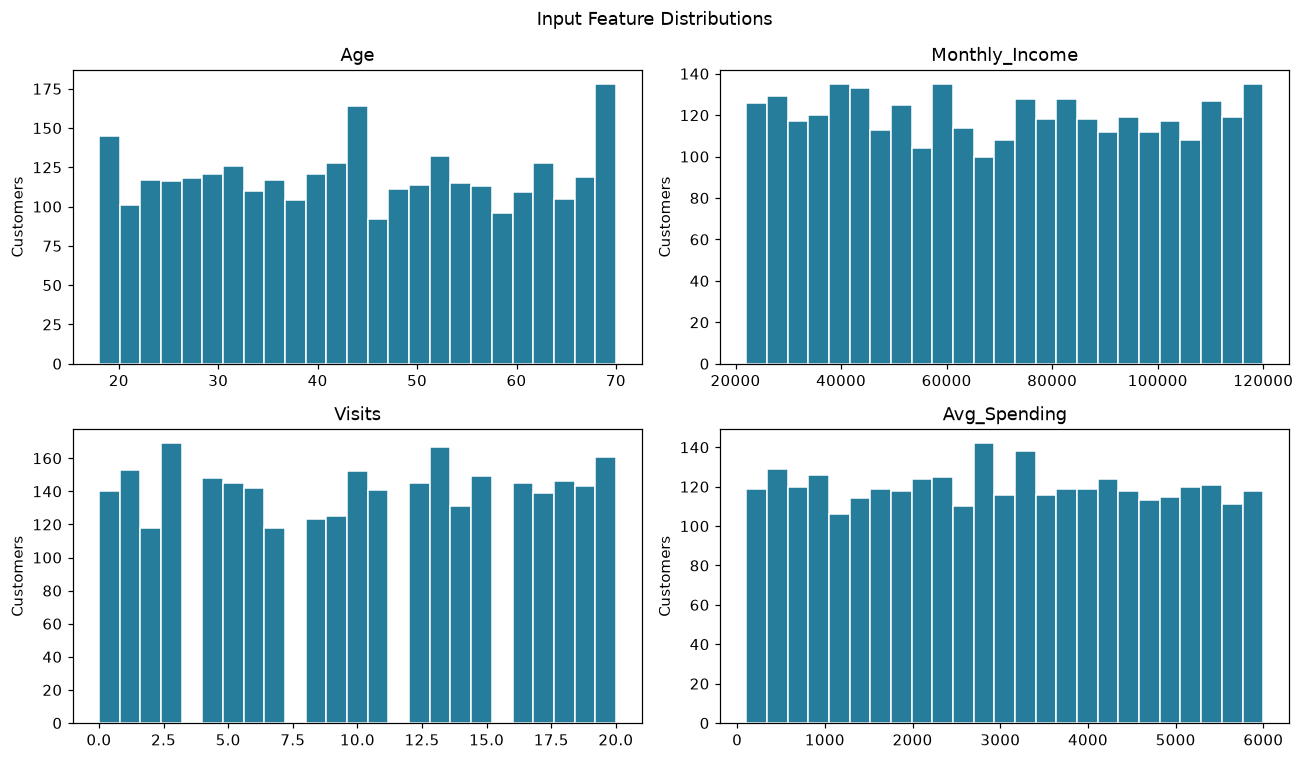

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, column in zip(axes.ravel(), valid_ranges):
    ax.hist(df[column], bins=25, color="#257c9b", edgecolor="white")
    ax.set_title(column)
    ax.set_ylabel("Customers")
fig.suptitle("Input Feature Distributions")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_feature_distributions.png", dpi=160, bbox_inches="tight")
plt.show()


## 10. 步驟二：選擇 Features 與 Target

`Customer_ID` 只是識別碼，不代表可泛化的購買規律；`Purchased` 是答案，不能當輸入。使用明確欄位清單，可以避免新增欄位時不小心把答案或其他資訊帶進模型。

欄位順序是輸入規格的一部分。訓練時先 Age、再收入，新顧客也必須保持同樣順序，否則模型會把收入誤當年齡。


In [10]:
feature_columns = ["Age", "Monthly_Income", "Visits", "Avg_Spending"]
X = df[feature_columns].copy()  # 二維表格：(資料筆數, 4)
y = df["Purchased"].astype("int64").copy()  # 一維答案：(資料筆數,)
print("X shape：", X.shape)
print("y shape：", y.shape)
display(X.head())


X shape： (3000, 4)
y shape： (3000,)


,Age,Monthly_Income,Visits,Avg_Spending
0,27,36405,14,495
1,26,53217,15,3425
2,51,114530,19,462
3,25,79166,3,5463
4,51,59835,0,986


## 11. 步驟三：切分 Train / Test，並準備模型輸入

### 11.1 Train、Validation、Test 各自負責什麼？

| 資料集 | 本章比例 | 用途 | 可以更新模型參數嗎？ |
| --- | --- | --- | --- |
| Train | 60% | 用答案計算梯度、學 Weight 與 Bias | 可以 |
| Validation | 20% | 挑選訓練輪數、觀察過度擬合 | 不透過梯度更新 |
| Test | 20% | 完成設計後評估未知資料表現 | 不可以 |

Test 先留起來，再把其餘資料切成 Train 與 Validation。這比只切 Train / Test 多一步，但能避免一直用 Test 挑選模型。隨機切分適合這份獨立合成顧客資料；時間預測應考慮時間切分，同一人多列則應採群組切分。

| `train_test_split` 參數 | 本章設定 | 用途 |
| --- | --- | --- |
| `test_size` | 0.2，第二次 0.25 | 決定分出去的比例 |
| `random_state` | 42 | 固定亂數分配，便於重做 |
| `stratify` | 對應的 y | 盡量維持兩種答案的比例 |

第二次是剩餘 80% 的 25%，所以 Validation 佔全部 20%。它不是再取全部的 25%。


In [11]:
X_train_valid, X_test, y_train_valid, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_valid, y_train_valid, test_size=0.25,
    random_state=SEED, stratify=y_train_valid
)

### 索引保留原始資料列位置，之後可對照顧客 ID
for name, features, target in [("Train", X_train, y_train),
                                ("Validation", X_valid, y_valid),
                                ("Test", X_test, y_test)]:
    print(f"{name}: {len(features)} 筆，購買比例={target.mean():.3f}")
assert set(X_train.index).isdisjoint(X_valid.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_valid.index).isdisjoint(X_test.index)


Train: 1800 筆，購買比例=0.513
Validation: 600 筆，購買比例=0.513
Test: 600 筆，購買比例=0.513


### 圖片規劃：切分與標準化的正確順序

圖片名稱：`06_data_split_scaling.png`  
尺寸：**1280 × 720，16:9**  
建議存放：`assets/v2/06_data_split_scaling.png`

> 提示詞：製作繁體中文深度學習教材示意圖。橫向 16:9，1280 × 720 px，白色背景，深藍標題、藍綠色重點、橘色強調，扁平向量資訊圖風格。字體大且清晰，資訊有留白，箭頭方向明確，不使用裝飾性假公式、不加浮水印。畫3000筆→Train1800、Validation600、Test600；只有Train連到fit StandardScaler，再由同一個scaler分別transform三組。Validation與Test不能連向fit。底部標示『先切分，再由Train學前處理參數』。

這是待製作圖片的規劃；目前先用相鄰文字與流程圖閱讀，不需要圖片也能完成本節。


### 11.2 標準化：把不同單位變成較接近的尺度

StandardScaler 對每個特徵減去 Train 的平均數，再除以 Train 的標準差。它不是把資料壓進 0～1，也不會把原本偏斜的分布自動變成常態分布。Train 轉換後平均約 0、標準差約 1；Validation 與 Test 不保證剛好如此。

- `fit_transform(X_train)`：先從 Train 學統計量，再轉換 Train。
- `transform(X_valid)`：沿用 Train 的統計量，不重新學習。
- `transform(X_test)`：也是同一組統計量。

預設 `with_mean=True`、`with_std=True`，本章直接採預設。負值通常表示低於訓練平均，不代表原始收入是負的。這次只標準化 Features；二元 Target 保持 0/1。


In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)

### 保留欄位名稱，方便對照轉換前後
display(pd.DataFrame(X_train_scaled[:5], columns=feature_columns))
display(pd.DataFrame({"Feature": feature_columns,
                      "Train mean": scaler.mean_, "Train scale": scaler.scale_}))


,Age,Monthly_Income,Visits,Avg_Spending
0,0.217309,1.166934,-0.667243,-0.218922
1,-0.177732,0.190136,1.129251,1.673440
2,1.402431,0.182864,-1.157196,-1.499535
3,0.019789,1.479947,1.292569,0.169677
4,-1.362854,1.379852,1.455886,-0.642260


,Feature,Train mean,Train scale
0,Age,44.699444,15.188307
1,Monthly_Income,70631.606111,28602.638597
2,Visits,10.085556,6.123036
3,Avg_Spending,3041.818889,1698.405860


### 11.3 轉 Tensor：特徵與答案的 shape 必須配對

模型最後輸出 `(N, 1)`，所以答案也整理成 `(N, 1)`。`reshape(-1, 1)` 的 `-1` 讓 PyTorch 自動推算筆數，`1` 表示每筆一個答案。

BCEWithLogitsLoss 的 Target 使用浮點 0.0/1.0；它與多類別 CrossEntropyLoss 常用整數類別索引不同。dtype 要依照 Loss 要求設定。

DataLoader 的訓練資料先放 CPU，每一批再搬到 device；這樣不需要一開始把所有訓練資料塞進 GPU。Validation 與 Test 很小，這裡整批放到 device 以簡化示範。


In [13]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)
X_valid_tensor = torch.tensor(X_valid_scaled, dtype=torch.float32).to(device)
y_valid_tensor = torch.tensor(y_valid.to_numpy(), dtype=torch.float32).reshape(-1, 1).to(device)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)

print("Train X：", tuple(X_train_tensor.shape), X_train_tensor.dtype)
print("Train y：", tuple(y_train_tensor.shape), y_train_tensor.dtype)


Train X： (1800, 4) torch.float32
Train y： (1800, 1) torch.float32


### 11.4 用 DataLoader 分批訓練

| 工具／參數 | 本章設定 | 意思 |
| --- | --- | --- |
| `TensorDataset(X, y)` | 特徵與答案 Tensor | 同一索引的 X 與 y 配成一對 |
| `batch_size` | 64 | 每次讀取最多 64 筆，計算一次更新 |
| `shuffle` | True | 每輪重新打亂 Train 順序 |
| `drop_last` | False | 保留最後不足 64 筆的一批 |
| `num_workers` | 0 | 在主程序讀資料，適合 Windows Notebook 入門 |
| `generator` | 固定種子的 Generator | 控制抽樣順序的亂數來源 |

**Batch** 是一次處理的一批資料；**Epoch** 是完整看過一次 Train。本章 1,800 筆、batch size 64，每輪有 29 次更新。最後一批只有 8 筆，仍保留。


In [14]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    drop_last=False, num_workers=0, generator=loader_generator
)
print("每個 Epoch 的批次數：", len(train_loader))


每個 Epoch 的批次數： 29


## 12. 步驟四：建立模型

### 12.1 把問題對應到架構

4 個 Features → 16 → 8 → 1 個 Logit。`len(feature_columns)` 自動取得輸入欄位數，避免新增 Features 後忘記同步修改。

`model.to(device)` 把參數移到選定裝置。模型與輸入必須在相同裝置。只搬模型、沒有搬資料會發生裝置不一致錯誤。

`nn.ReLU()` 不需要指定神經元個數，也沒有本章要學習的參數。`nn.Sequential` 的順序就是前向傳播順序。


In [15]:
### 重新建立模型前固定種子，減少前面示範對初始化的影響
torch.manual_seed(SEED)
model = nn.Sequential(
    nn.Linear(in_features=len(feature_columns), out_features=16, bias=True),
    nn.ReLU(),
    nn.Linear(in_features=16, out_features=8, bias=True),
    nn.ReLU(),
    nn.Linear(in_features=8, out_features=1, bias=True),
).to(device)
print(model)

### 列出每組參數的 shape 與數量
parameter_table = pd.DataFrame([
    {"Name": name, "Shape": str(tuple(parameter.shape)), "Count": parameter.numel()}
    for name, parameter in model.named_parameters()
])
display(parameter_table)
print("總參數：", parameter_table["Count"].sum())  # 225


Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
)
總參數： 225


,Name,Shape,Count
0,0.weight,"(16, 4)",64
1,0.bias,"(16,)",16
2,2.weight,"(8, 16)",128
3,2.bias,"(8,)",8
4,4.weight,"(1, 8)",8
5,4.bias,"(1,)",1


### 12.2 Loss Function：用一個分數衡量差距

本章使用 `nn.BCEWithLogitsLoss()`。模型最後直接輸出 Logit；Loss 內部整合穩定的 Sigmoid 與二元交叉熵運算，因此**不要先對 Logit 做 Sigmoid 再送進這個 Loss**。預測時才另外轉換機率。

預設 `reduction="mean"` 表示取該批資料的平均損失。Loss 越低通常表示預測分數與答案更一致，但 Loss 不是錯誤率；Loss=0.3 不代表錯了 30%。

### 12.3 Optimizer：實際調整 Weight 與 Bias

`Adam(model.parameters(), lr=0.001)`：第一個參數指定要更新的模型參數，`lr` 是 Learning Rate（學習率），控制更新步幅。太大可能不穩定，太小可能學得慢。Adam 根據梯度的歷史統計調整更新，不保證永遠優於其他方法。

本章保留 Adam 其他預設設定，例如 `betas=(0.9, 0.999)` 控制歷史梯度統計的平滑、`eps=1e-8` 避免除以極小值、`weight_decay=0` 表示此處未加入權重衰減。入門先調 `lr`，不要同時修改所有參數。

### 12.4 模型參數與超參數

| 類型 | 例子 | 如何決定 |
| --- | --- | --- |
| 模型參數 | Weight、Bias | 從 Train 學到 |
| 超參數 | 隱藏層寬度、lr、batch size、epochs | 由人設定，依 Validation 比較 |
| 決策設定 | 分類門檻 | 依任務成本與 Validation 選擇 |


In [16]:
criterion = nn.BCEWithLogitsLoss(reduction="mean")
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)


## 13. 步驟五：訓練模型

### 13.1 一批資料的五個必要動作

```text
zero_grad → model(X) → criterion(logits, y) → loss.backward → optimizer.step
清梯度       前向傳播       計算差距              算梯度            更新參數
```

PyTorch 預設會累加梯度，所以這裡每批先清空。`loss.backward()` 計算梯度，`optimizer.step()` 才真正更新參數。

`model.train()` 與 `model.eval()` 設定訓練／評估模式。現在沒有 Dropout 或 BatchNorm，模式不會改變這個模型的數值運作；仍保留正確習慣，方便未來擴充。**eval 不等於關閉梯度**，驗證時仍搭配 `torch.no_grad()`。

### 13.2 何時停止？

最多訓練 150 輪，根據 Validation Loss 保存最佳參數。連續 20 輪沒有至少 0.0001 的改善就停止，稱為 Early Stopping。停止後回復最佳版本，避免直接拿最後一輪評估。

- `MAX_EPOCHS`：上限，並非越多越好。
- `PATIENCE`：容忍幾輪沒有足夠改善。
- `min_delta=0.0001`：本章判定明顯改善的幅度。
- `deepcopy(state_dict())`：複製當時參數，避免後續更新把最佳紀錄一起改掉。

下面每輪結束後，會用同一份「當輪更新後的模型」重新計算 Train 與 Validation Loss。兩條曲線因此能在相同參數狀態下比較；這與把訓練過程中不同批次的 Loss 直接平均略有不同。


In [17]:
history = []
best_valid_loss = float("inf")
best_state = None
best_epoch = 0
epochs_without_improvement = 0
min_delta = 0.0001

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad(set_to_none=True)  # 清除上一批梯度，設為 None
        batch_logits = model(batch_X)          # Forward，shape=(本批筆數, 1)
        batch_loss = criterion(batch_logits, batch_y)
        batch_loss.backward()                  # 計算梯度
        optimizer.step()                       # 更新 Weight 與 Bias

    ### 以更新後的同一個模型評估兩組 Loss，不再更新參數
    model.eval()
    with torch.no_grad():
        train_eval_logits = model(X_train_tensor.to(device))
        train_loss_value = criterion(train_eval_logits, y_train_tensor.to(device)).item()
        valid_eval_logits = model(X_valid_tensor)
        valid_loss_value = criterion(valid_eval_logits, y_valid_tensor).item()
    history.append({"Epoch": epoch, "Train_Loss": train_loss_value,
                    "Valid_Loss": valid_loss_value})

    ### 只根據 Validation 決定最佳輪數
    if valid_loss_value < best_valid_loss - min_delta:
        best_valid_loss = valid_loss_value
        best_state = deepcopy(model.state_dict())
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(f"Epoch {epoch:3d} | Train={train_loss_value:.4f} | Valid={valid_loss_value:.4f}")
    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping：連續 {PATIENCE} 輪沒有足夠改善。")
        break

### 後續統一使用最佳驗證版本
model.load_state_dict(best_state)
model.eval()
history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False, encoding="utf-8-sig")
print(f"最佳輪數：{best_epoch}，Validation Loss：{best_valid_loss:.4f}")


Epoch   1 | Train=0.7074 | Valid=0.7071
Epoch  10 | Train=0.4666 | Valid=0.4705
Epoch  20 | Train=0.4610 | Valid=0.4702
Epoch  30 | Train=0.4592 | Valid=0.4711
Early stopping：連續 20 輪沒有足夠改善。
最佳輪數：12，Validation Loss：0.4686


### 13.3 訓練結果該如何閱讀？

先看第一輪到最佳輪的 Loss 是否有下降，再看 Train 與 Validation 的差距。不要只看最後印出的數字：最後一輪未必是被保留下來的模型。

| 曲線現象 | 可能情況 | 接下來可以檢查 |
| --- | --- | --- |
| 兩者下降後趨緩 | 正在學習，後期改善有限 | 基準與測試指標 |
| Train 下降、Validation 持續上升 | 可能過度擬合 | 提早停止、縮小模型、增加有效資料 |
| 兩者都很高 | 可能欠擬合或流程有問題 | 欄位、標準化、lr、訓練輪數 |
| Loss 變 NaN 或劇烈震盪 | 可能有無效數值或步幅過大 | 輸入是否有限值、lr 是否過大 |

這些是排查線索，不是單憑曲線就能確定的診斷。Loss 圖會在步驟八與預測圖表一起畫出。


## 14. 步驟六：使用模型預測

現在才使用保留的 Test。先取得 Logit，再 Sigmoid，最後套用預先固定的門檻 0.5。`ravel()` 把 `(N, 1)` 整理成 sklearn 需要的一維 `(N,)`。

建立結果表時沿用 `X_test.index` 找回 ID 與答案，避免因切分順序不同，把 A 顧客的預測接到 B 顧客身上。


In [18]:
model.eval()
with torch.no_grad():
    test_logits = model(X_test_tensor)
    test_probabilities = torch.sigmoid(test_logits)

y_prob = test_probabilities.detach().cpu().numpy().ravel()
y_pred = (y_prob >= THRESHOLD).astype(int)
y_true = y_test.to_numpy()

### 原始特徵、真實答案與預測結果放在一起
test_results = df.loc[X_test.index, ["Customer_ID"] + feature_columns].copy()
test_results["Actual"] = y_true
test_results["Purchase_Probability"] = y_prob
test_results["Prediction"] = y_pred
test_results["Correct"] = y_true == y_pred
display(test_results.head(10))
test_results.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False, encoding="utf-8-sig")


,Customer_ID,Age,Monthly_Income,Visits,Avg_Spending,Actual,Purchase_Probability,Prediction,Correct
1925,C01926,49,112968,2,3035,0,0.269541,0,True
2207,C02208,36,64042,20,4645,1,0.949655,1,True
2755,C02756,40,49470,14,2771,1,0.597510,1,True
2202,C02203,25,105167,3,478,0,0.192189,0,True
2519,C02520,70,66958,7,1138,1,0.104289,0,False
1140,C01141,66,51846,20,2105,1,0.791021,1,True
559,C00560,65,71765,2,406,0,0.055526,0,True
1849,C01850,30,93344,20,418,0,0.730957,1,False
2773,C02774,53,74223,4,5474,1,0.422499,0,False
97,C00098,19,101450,14,5155,1,0.931141,1,True


## 15. 步驟七：評估模型表現

### 15.1 各指標在回答什麼？

把「購買 = 1」當作正類。

| 指標 | 白話問題 | 注意事項 |
| --- | --- | --- |
| Accuracy | 全部顧客中，多少比例猜對？ | 類別不平衡時可能誤導 |
| Precision | 被模型判為購買者的人，有多少真的購買？ | 關心誤報成本 |
| Recall | 真正購買的人，有多少被找出來？ | 關心漏掉潛在顧客 |
| F1 | Precision 與 Recall 是否同時兼顧？ | 不包含真負類的直接貢獻 |
| ROC AUC | 模型把購買者排在不購買者前面的能力如何？ | 使用機率分數，不能傳 0/1 類別 |

ROC AUC 約 0.5 表示接近隨機排序、1 表示完美排序。它不是「預測正確率」，也不能保證機率校準良好。Accuracy、Precision、Recall 與 F1 都會受到門檻影響。

`zero_division=0` 在沒有預測正類等情況下，將無法定義的指標設成 0；如果真的出現，應檢查模型是不是只預測同一類。

### 15.2 加上基準，才能知道 ANN 的成績代表什麼

先比較「全部猜 Train 多數類別」與 Logistic Regression。Logistic Regression 使用同一份切分、相同標準化，並只用 Train 訓練。這不是完整的模型競賽，也不宣稱 ANN 一定勝出；它提供一個簡單模型能做到多少的參考。

基準設定與 ANN 架構在查看 Test 前已固定。若看完 Test 後繼續大量改模型，這組 Test 就不再是乾淨的最終評估，應改用 Validation 反覆比較，另保留最終測試資料。


In [19]:
### 多數類別基準：只從 Train 決定要猜哪一類
majority_class = int(y_train.mode().iloc[0])
majority_pred = np.full(len(y_test), majority_class)
majority_prob = np.full(len(y_test), float(y_train.mean()))  # 所有人相同分數

### 簡單模型基準，不使用 Validation 或 Test 訓練
baseline = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)
baseline.fit(X_train_scaled, y_train)
baseline_prob = baseline.predict_proba(X_test_scaled)[:, 1]
baseline_pred = (baseline_prob >= THRESHOLD).astype(int)

### 同一組 Test、同一套指標進行比較
def calculate_metrics(model_name, true_values, predicted_values, probabilities):
    return {"Model": model_name,
            "Accuracy": accuracy_score(true_values, predicted_values),
            "Precision": precision_score(true_values, predicted_values, zero_division=0),
            "Recall": recall_score(true_values, predicted_values, zero_division=0),
            "F1": f1_score(true_values, predicted_values, zero_division=0),
            "ROC_AUC": roc_auc_score(true_values, probabilities)}

metrics_df = pd.DataFrame([
    calculate_metrics("Majority", y_true, majority_pred, majority_prob),
    calculate_metrics("Logistic Regression", y_true, baseline_pred, baseline_prob),
    calculate_metrics("ANN", y_true, y_pred, y_prob),
]).set_index("Model")
display(metrics_df.round(4))
metrics_df.to_csv(OUTPUT_DIR / "model_metrics.csv", encoding="utf-8-sig")
print(classification_report(y_true, y_pred, labels=[0, 1],
                            target_names=["Not Purchased", "Purchased"], zero_division=0))


               precision    recall  f1-score   support

Not Purchased       0.76      0.74      0.75       292
    Purchased       0.76      0.78      0.77       308

     accuracy                           0.76       600
    macro avg       0.76      0.76      0.76       600
 weighted avg       0.76      0.76      0.76       600



,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Majority,0.5133,0.5133,1.0000,0.6784,0.5000
Logistic Regression,0.7517,0.7492,0.7760,0.7624,0.8552
ANN,0.7600,0.7595,0.7792,0.7692,0.8546


`LogisticRegression` 的 `C=1.0` 控制正則化強度的倒數，越小限制越強；`max_iter=1000` 是其求解器的最大迭代數，不等同 ANN 的 Epoch。`predict_proba(... )[:, 1]` 取得類別 1 的機率。

### 解讀練習

請根據自己的輸出寫三句話：ANN 與多數基準相差多少？ANN 與 Logistic Regression 的 F1／AUC 誰較高？若 ANN 沒有勝過簡單模型，是否仍值得增加複雜度？

不要替未執行的模型先寫固定成績，也不要只挑最好看的一個指標。這份合成資料含有隨機性，預測錯誤不一定表示程式寫錯。


## 16. 步驟八：視覺化預測結果

### 16.1 Loss 曲線：訓練過程是否合理？

虛線標示實際採用的最佳輪數。Validation 較 Train 高一些很常見，但重點是趨勢、差距與最終未知資料表現，不能硬性要求每一輪都下降。


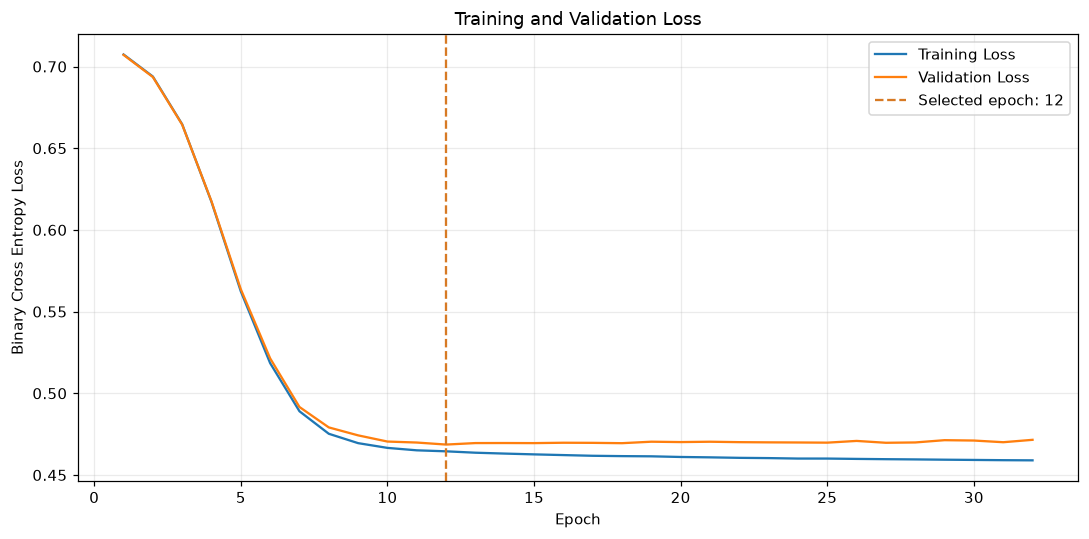

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history_df["Epoch"], history_df["Train_Loss"], label="Training Loss")
ax.plot(history_df["Epoch"], history_df["Valid_Loss"], label="Validation Loss")
ax.axvline(best_epoch, color="#d77a24", linestyle="--", label=f"Selected epoch: {best_epoch}")
ax.set(title="Training and Validation Loss", xlabel="Epoch", ylabel="Binary Cross Entropy Loss")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_loss_curves.png", dpi=160, bbox_inches="tight")
plt.show()


### 16.2 混淆矩陣：錯在哪一種情況？

`from_predictions` 圖的縱軸是 Actual（真實），橫軸是 Predicted（預測）。

| 位置 | 名稱 | 本題的意思 |
| --- | --- | --- |
| 左上，真 0／預 0 | TN | 正確判斷不購買 |
| 右上，真 0／預 1 | FP | 誤以為會購買，可能浪費行銷資源 |
| 左下，真 1／預 0 | FN | 漏掉真正購買者 |
| 右下，真 1／預 1 | TP | 正確找出購買者 |

`labels=[0, 1]` 固定類別順序；`display_labels` 設定文字；`cmap` 設色盤；`values_format="d"` 顯示整數筆數。圖中的人數加起來應等於 Test 筆數。


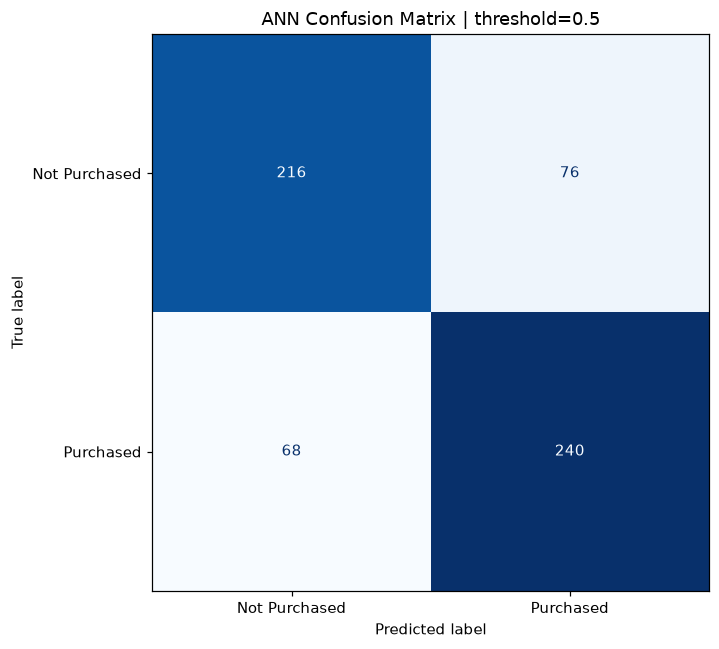

In [21]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=[0, 1], display_labels=["Not Purchased", "Purchased"],
    cmap="Blues", values_format="d", colorbar=False, ax=ax
)
ax.set_title(f"ANN Confusion Matrix | threshold={THRESHOLD}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()


### 16.3 ROC 曲線與機率分布

ROC 的橫軸是假正率 FPR（實際不購買者有多少被誤判購買），縱軸是真正率 TPR，也就是 Recall。曲線對應一系列門檻，不只是目前的 0.5。

機率分布把真實為 0 與真實為 1 的人分開畫。如果兩組大量重疊，表示模型不容易清楚區分。靠近 0.5 的顧客對門檻特別敏感；高機率也可能判錯。


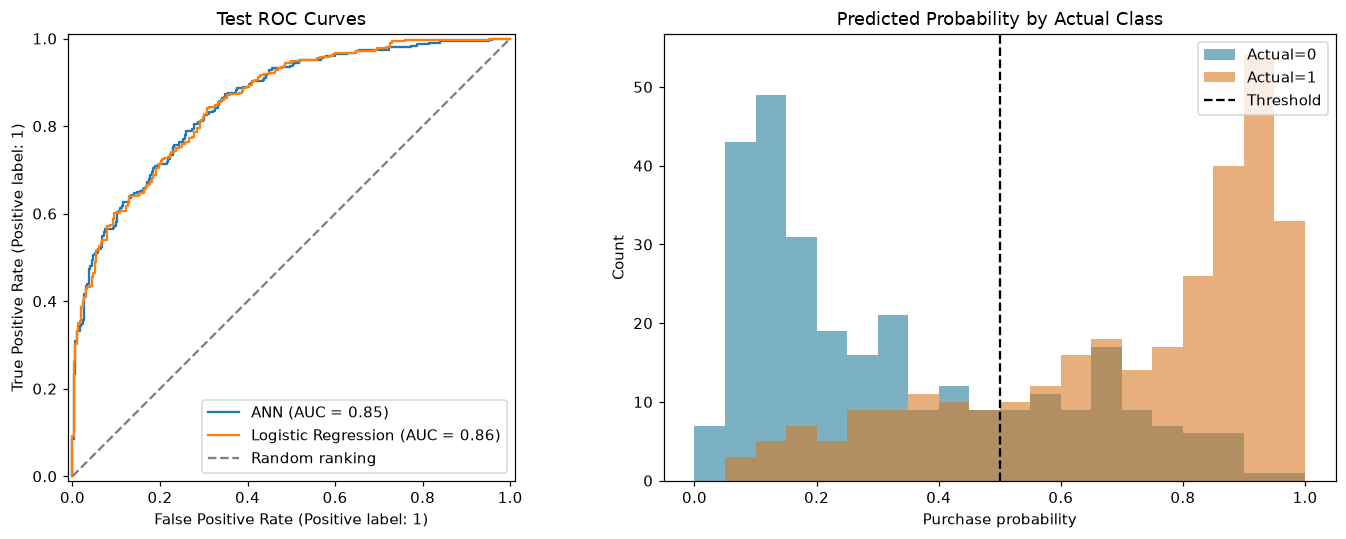

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_true, y_prob, name="ANN", ax=axes[0])
RocCurveDisplay.from_predictions(y_true, baseline_prob, name="Logistic Regression", ax=axes[0])
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
axes[0].set_title("Test ROC Curves")
axes[0].legend()

### 共同 bins 才能讓兩組分布直接比較
probability_bins = np.linspace(0, 1, 21)
for label, color in [(0, "#257c9b"), (1, "#d77a24")]:
    axes[1].hist(y_prob[y_true == label], bins=probability_bins, alpha=0.6,
                 color=color, label=f"Actual={label}")
axes[1].axvline(THRESHOLD, linestyle="--", color="black", label="Threshold")
axes[1].set(title="Predicted Probability by Actual Class", xlabel="Purchase probability", ylabel="Count")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_roc_and_probabilities.png", dpi=160, bbox_inches="tight")
plt.show()


### 16.4 看幾筆錯誤，不急著下因果結論

先找高信心但錯誤的案例，檢查是否有欄位對錯、資料來源或時間定義問題。不能只看一位高收入顧客沒買，就斷言收入沒有影響。這裡有隨機標籤生成與未建模因素，不可能透過四個欄位還原每一次行為。


In [23]:
### 正確類別的機率越低，代表這個錯誤越有信心
error_results = test_results.loc[~test_results["Correct"]].copy()
error_results["True_Class_Probability"] = np.where(
    error_results["Actual"] == 1, error_results["Purchase_Probability"],
    1 - error_results["Purchase_Probability"]
)
display(error_results.sort_values("True_Class_Probability").head(10))


,Customer_ID,Age,Monthly_Income,Visits,Avg_Spending,Actual,Purchase_Probability,Prediction,Correct,True_Class_Probability
535,C00536,62,88403,20,4046,0,0.955975,1,False,0.044025
2909,C02910,52,62623,0,1604,1,0.059297,0,False,0.059297
2843,C02844,67,22638,1,5349,1,0.063958,0,False,0.063958
1299,C01300,41,74223,12,5556,0,0.912842,1,False,0.087158
2893,C02894,70,87569,2,2696,1,0.098452,0,False,0.098452
2519,C02520,70,66958,7,1138,1,0.104289,0,False,0.104289
2428,C02429,66,105411,16,3007,0,0.891944,1,False,0.108056
2774,C02775,55,52915,4,3104,1,0.111649,0,False,0.111649
2463,C02464,52,53159,4,2794,1,0.113673,0,False,0.113673
987,C00988,38,117872,13,3596,0,0.885362,1,False,0.114638


## 17. 真正的新資料：預測三位新顧客

Test 已知答案只是用來評估。現在輸入沒有 Target 的新顧客，模擬實際使用。

必須沿用四件事：**Features 欄位與順序、訓練時的 scaler、訓練好的模型、預先決定的門檻**。不能對三位新顧客重新 `fit_transform`，也不能重新建立一個隨機模型就拿來預測。

下例新資料也附在 `data/new_customers_v2.csv`。它們沒有真實 Target，因此只能產生預測，不能計算 Accuracy。


In [24]:
new_customers = pd.read_csv(BASE_DIR / "data/new_customers_v2.csv")
new_X = new_customers[feature_columns]  # 明確保持欄位順序
new_X_scaled = scaler.transform(new_X)  # 只 transform，不 fit
new_X_tensor = torch.tensor(new_X_scaled, dtype=torch.float32).to(device)

model.eval()
with torch.no_grad():
    new_prob = torch.sigmoid(model(new_X_tensor)).cpu().numpy().ravel()

new_results = new_customers.copy()
new_results["Purchase_Probability"] = new_prob
new_results["Prediction"] = (new_prob >= THRESHOLD).astype(int)
display(new_results)
new_results.to_csv(OUTPUT_DIR / "new_customer_predictions.csv", index=False, encoding="utf-8-sig")


,Customer_ID,Age,Monthly_Income,Visits,Avg_Spending,Purchase_Probability,Prediction
0,NEW001,25,32000,2,600,0.068373,0
1,NEW002,40,85000,16,4500,0.926213,1
2,NEW003,62,58000,8,2200,0.165595,0


## 18. 延伸：保存與重新載入

只保存 Weight 還不夠，預測時也需要相同架構、前處理統計與欄位順序。本章保存模型的 `state_dict`，並把 StandardScaler 的統計量、門檻與環境寫入 JSON。

`state_dict` 是參數字典，不包含整個 Python 程式。重新載入時，要先建立相同架構。`map_location="cpu"` 讓 GPU 訓練的權重也能在 CPU 載入；`weights_only=True` 只讀取這份權重資料。請只載入可信來源的模型檔。

為了把保存結果檢查清楚，下面真的建立另一個模型，重新處理新顧客資料，並驗證前後機率一致。


In [25]:
### 將最佳模型權重轉成 CPU 後保存，方便跨裝置載入
cpu_state = {name: value.detach().cpu() for name, value in model.state_dict().items()}
torch.save(cpu_state, OUTPUT_DIR / "ann_weights.pt")
preprocessing_config = {
    "feature_columns": feature_columns,
    "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
    "threshold": THRESHOLD, "architecture": [4, 16, 8, 1],
    "best_epoch": best_epoch, "run_info": run_info
}
(OUTPUT_DIR / "preprocessing.json").write_text(
    json.dumps(preprocessing_config, ensure_ascii=False, indent=2), encoding="utf-8"
)

### 以下可以搬到另一份程式，但需先匯入所用套件並設定檔案路徑
loaded_config = json.loads((OUTPUT_DIR / "preprocessing.json").read_text(encoding="utf-8"))
loaded_model = nn.Sequential(
    nn.Linear(4, 16), nn.ReLU(), nn.Linear(16, 8), nn.ReLU(), nn.Linear(8, 1)
)
loaded_model.load_state_dict(torch.load(OUTPUT_DIR / "ann_weights.pt", map_location="cpu", weights_only=True))
loaded_model.eval()

### 還原這份 StandardScaler 的轉換：減去 mean，再除以 scale
loaded_new_X = new_customers[loaded_config["feature_columns"]].to_numpy(dtype=np.float64)
loaded_scaled_X = ((loaded_new_X - np.array(loaded_config["scaler_mean"]))
                   / np.array(loaded_config["scaler_scale"]))
with torch.no_grad():
    loaded_prob = torch.sigmoid(loaded_model(torch.tensor(loaded_scaled_X, dtype=torch.float32))).numpy().ravel()
np.testing.assert_allclose(new_prob, loaded_prob, rtol=1e-4, atol=1e-6)
print("重新載入檢查通過，預測機率：", loaded_prob)


重新載入檢查通過，預測機率： [0.06837265 0.92621255 0.16559458]


## 19. 常見錯誤與修正方向

| 現象 | 常見原因 | 檢查方式 |
| --- | --- | --- |
| `ModuleNotFoundError: torch` | 安裝環境與 Kernel 不同 | 查看 `sys.executable`，選正確 Kernel |
| 找不到 CSV | 工作目錄不符，或只複製 Notebook | 保留 data 資料夾，查看 DATA_PATH |
| `mat1 and mat2 shapes cannot be multiplied` | 第一層輸入維度或欄位數不符 | 對照 X.shape 與 in_features |
| Target size 與 input size 不同 | y 是 `(N,)`，Logit 是 `(N,1)` | 轉 float32 並 `reshape(-1,1)` |
| dtype 不一致 | NumPy float64、模型 float32 | 轉 Tensor 時指定 float32 |
| 裝置不一致 | 模型在 GPU，資料在 CPU | 對模型與 batch 使用 `.to(device)` |
| 轉 NumPy 失敗 | Tensor 在 GPU 或仍追蹤梯度 | `.detach().cpu().numpy()` |
| Loss 不降或發散 | 尺度、lr、答案或資料有問題 | 先檢查資料，再逐項調整 |
| 評估非常好，上線很差 | 洩漏、分布改變或切分不當 | 重新檢查預測時點與切分單位 |
| 重跑後結果不同 | 沒有重新初始化模型／Optimizer | Restart Kernel 後 Run All |

單獨再跑一次訓練儲存格會從目前權重繼續訓練。公平比較兩次設定時，應重新執行模型建立、Optimizer 建立與訓練流程，最好直接 Restart Kernel → Run All。


## 20. 動手練習：從會執行到會判斷

### 練習一：解釋架構

把模型改成 `4 → 8 → 1`，每個隱藏層後接 ReLU。先算參數量，再用程式核對。答案是 `(4×8+8)+(8×1+1)=49`。同步修改保存與載入架構，避免讀取不相容的權重。

### 練習二：調整一個超參數

分別比較 `lr=0.0003`、`0.001`、`0.003`，每次重新初始化模型與 Optimizer，其餘設定固定。先以 Validation Loss 選擇，記錄最佳輪數，確定方案後才做最終 Test。不能只因為某次 Test 特別高，就說那個學習率最好。

### 練習三：在 Validation 比較門檻

下面刻意只對 Validation 計算 Precision、Recall、F1。觀察調低門檻後，Recall 與 Precision 的取捨。這是額外練習，不會回頭改寫前面 Test 成績。


In [26]:
with torch.no_grad():
    valid_prob = torch.sigmoid(model(X_valid_tensor)).cpu().numpy().ravel()
threshold_rows = []
for candidate_threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    candidate_pred = (valid_prob >= candidate_threshold).astype(int)
    threshold_rows.append({
        "Threshold": candidate_threshold,
        "Precision": precision_score(y_valid, candidate_pred, zero_division=0),
        "Recall": recall_score(y_valid, candidate_pred, zero_division=0),
        "F1": f1_score(y_valid, candidate_pred, zero_division=0)
    })
display(pd.DataFrame(threshold_rows).round(4))


,Threshold,Precision,Recall,F1
0,0.3,0.7150,0.8961,0.7954
1,0.4,0.7352,0.8474,0.7873
2,0.5,0.7732,0.7857,0.7794
3,0.6,0.8231,0.6948,0.7535
4,0.7,0.8738,0.5844,0.7004


### 練習四：移除一個 Feature

試著移除 Age，輸入層改為 3 個輸入。先猜 Validation 成績會如何，再執行完整資料準備與訓練。單次小幅差異可能只是隨機波動，不能直接下因果結論。

### 練習五：把結果說給沒有學過深度學習的人聽

用三句話交代：模型輸入什麼、如何評估、有哪些限制。不要只說「ANN 有 225 個參數」，要說明這個預測如何被判斷是否有用。

### 觀念問答與參考答案

| 問題 | 參考答案 |
| --- | --- |
| 資料多一倍，in_features 要加倍嗎？ | 不用，取決於每筆資料的 Features 數 |
| Hidden Layer 的 16 是答案類別數嗎？ | 不是，是設計的隱藏表示寬度 |
| 為什麼模型最後不加 Sigmoid？ | 本章 Loss 直接接收 Logit，避免重複轉換 |
| eval 會自動停止梯度追蹤嗎？ | 不會，仍需 no_grad 等機制 |
| Weight 是誰決定的？ | 初始化後，由訓練資料與更新流程調整 |
| Bias 就是分類門檻嗎？ | 不是，Bias 是各神經元的可學習參數 |
| 新資料可以重新 fit scaler 嗎？ | 不行，沿用訓練時的統計量 |
| ANN 一定勝過 Logistic Regression 嗎？ | 不一定，要比較驗證與測試結果 |
| AUC 0.8 代表 80% 分類正確嗎？ | 不是，它衡量排序區分能力 |


## 21. 搬到 Notion 的整理方式

Notebook 是可以執行的原始教材。附帶的 `深度學習基礎_v2_Notion.md` 是相同內容的 Markdown 副本，供你匯入 Notion 後整理標題、表格與程式碼；它不會自動建立或發佈 Notion 頁面。

建議先在 Notebook 執行確認，再把實際產出的圖表與評估數字放到對應段落。Markdown 副本保留程式碼，但不會自動帶入你後續重跑的輸出；可從 `outputs/v2` 取得圖表與 CSV。

圖片提示詞已放在各概念後面，並集中於 `圖片提示詞_v2.md`。等你生成圖片後，再把檔案放到 `assets/v2`，於需要的位置加入 `![](assets/v2/圖片名稱.png)`，或直接上傳至 Notion。所有規劃示意圖皆為 **16:9、1280 × 720**；本次沒有生成示意圖片。

### 完成後的自我檢查

- 能解釋 Weight、Bias、加權總和與非線性的角色。
- 能依 Features 與任務設定輸入與輸出數量。
- 只使用 Train 學習 scaler 與模型參數。
- 用 Validation 選輪數，完成方案後再評估 Test。
- 機率、類別、Loss 與評估指標沒有混為一談。
- 新資料與重新載入模型都能沿用同一套輸入規格。


## 22. 官方延伸閱讀

以下是本教材 API 行為與安裝資訊的核對來源；教材文字與教學例子以自行整理的說明為主。安裝組合可能變動，請以實際環境與官方選擇器為準。

- [PyTorch：安裝選擇器](https://pytorch.org/get-started/locally/)
- [PyTorch：Learn the Basics](https://docs.pytorch.org/tutorials/beginner/basics/intro.html)
- [PyTorch：Linear](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html)
- [PyTorch：BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html)
- [PyTorch：Optimization Loop](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html)
- [PyTorch：Adam](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html)
- [scikit-learn：train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
- [scikit-learn：StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
